# FXS / 10 — When does each signal work? Five pre-entry conditioners (2020 → 2026-11)

Pre-registration: `discussions/FX_Intraday_Seasonality/005_claude_fxs10_conditioners_preregistration.md`.

The 12 signals of FXS 09, each split by conditions known **before** entry:

| # | Conditioner | Buckets |
|---|---|---|
| C1 | Tokyo date of entry is a gotobi day | gotobi / other |
| C2 | 20-day realized volatility (through previous close) | high / low vs training median |
| C3 | 60-day trend × trade direction | with / against |
| C4 | move from the day start to entry × trade direction | continuation / reversal |
| C5a | day of week | Mon … Fri |
| C5b | last two trading days of the month | month-end / other |

- **A.** Buckets over 2020–2026 pooled (in sample, descriptive).
- **B.** Walk-forward 2021–2026: each year's trade/skip rule uses only earlier years (training starts in 2020). Compared with the unfiltered signal and with **C0** (trade the signal only if its own past is positive).
- **C.** The 12-signal portfolio with each filter, $6,000, 1–10×.

All results in **net pips** ($3 per lot, 0.9 × Dukascopy spread).

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
COMMISSION_PER_LOT = 3.0
SPREAD_FACTOR = 0.9
MIN_BUCKET = 30          # buckets with fewer training trades are traded
WINDOWS = ((dt.date(2020, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
LOOKBACK = (dt.date(2019, 8, 1), dt.date(2019, 12, 31), "discovery")    # features only (60-day trend, 20-day vol)
TEST_YEARS = list(range(2021, 2027))
SIGNALS = {
    "EURUSD-02": ("EURUSD", "NY", 660, 900, -1), "USDJPY-01": ("USDJPY", "UTC", 55, 115, -1), "USDJPY-02": ("USDJPY", "UTC", 25, 55, 1),
    "N-EU-1": ("EURUSD", "NY", 885, 900, -1), "N-UJ-1": ("USDJPY", "UTC", 55, 70, -1), "N-UJ-3": ("USDJPY", "NY", 1340, 1400, 1),
    "N-EJ-1": ("EURJPY", "NY", 1315, 1435, 1), "N-EJ-2": ("EURJPY", "NY", 780, 900, -1),
    "AUDJPY-N1": ("AUDJPY", "NY", 1195, 1435, 1), "AUDJPY-N2": ("AUDJPY", "UTC", 60, 180, 1), "CADJPY-N1": ("CADJPY", "NY", 1070, 1310, 1),
    "GBPJPY-N1": ("GBPJPY", "NY", 1195, 1435, 1)}
COND = ["C1 gotobi", "C2 vol", "C3 trend", "C4 pre-entry move", "C5a weekday", "C5b month-end"]

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs10_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import gotobi as GT

cfg = F.FXSConfig()
OUT = Path.cwd() / ("10_synthetic" if SYNTHETIC else "10"); OUT.mkdir(exist_ok=True)
cand = pd.DataFrame([{"id": k, "pair": p, "clock": c, "start": s, "end": e, "direction": d} for k, (p, c, s, e, d) in SIGNALS.items()])
PAIRS = sorted(set(cand["pair"]))
PAIR_OF = cand.set_index("id")["pair"]
pd.set_option("display.width", 240, "display.max_columns", 40, "display.max_rows", 200)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(PAIRS):
        F.write_synthetic_candles(base, p, dt.date(2019, 7, 28), dt.date(2026, 11, 6), seed=61 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)

## 1. Trades and features

Previous-close features use the New York 17:00 close of the trading day before the signal's day (known before every entry, including the 00:25–01:00 UTC ones).

In [3]:
for p in PAIRS:
    for a, b, _ in (*WINDOWS, LOOKBACK):
        cov = F.file_coverage(p, a, b)
        assert cov["share"] >= cfg.min_file_share, f"{p} {a.year}: only {cov['share']:.1%} of day files"
G, P, PRE, closes = [], [], {i: [] for i in SIGNALS}, {p: [] for p in PAIRS}
for a, b, st in WINDOWS:
    panels = F.load_panels(PAIRS, a, b, st, cfg)
    g, _, pr = F.structure_detail(cand, a, b, st, cfg, panels=panels, with_price=True, spread_factor=SPREAD_FACTOR)
    G.append(g); P.append(pr)
    for _, r in cand.iterrows():                     # C4: day start -> entry, in trade direction (bps)
        pn = panels[(r["pair"], r["clock"])]
        lm = np.log(pn.mid)
        PRE[r["id"]].append(pd.Series((lm[:, int(r["start"])] - lm[:, 0]) * 1e4 * r["direction"], index=pd.to_datetime(pn.dates)))
    for p in PAIRS:
        pn = panels[(p, "NY")]
        closes[p].append(pd.Series(pn.mid[:, -1], index=pd.to_datetime(pn.dates)))
    del panels
lb = F.load_panels(PAIRS, *LOOKBACK, cfg, clocks=("NY",))
for p in PAIRS:
    closes[p].insert(0, pd.Series(lb[(p, "NY")].mid[:, -1], index=pd.to_datetime(lb[(p, "NY")].dates)))
del lb
G = pd.concat(G).sort_index().fillna(0.0)
P = pd.concat(P).sort_index().ffill().bfill()
comm = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], COMMISSION_PER_LOT) for i in G.columns})
traded = G != 0
NB = (G - comm).where(traded, 0.0)                                      # net bps, 0 on days without a trade
pips = pd.DataFrame({i: F.bps_to_pips(NB[i], P[i], PAIR_OF[i]) for i in G.columns}, index=G.index).where(traded)
idx = G.index

# features per signal, indexed like G
close = {p: pd.concat(v).sort_index().pipe(lambda s: s[~s.index.duplicated()]).dropna() for p, v in closes.items()}
vol20 = {p: np.log(c).diff().rolling(20).std().shift(1) for p, c in close.items()}       # through previous close
tr60 = {p: (np.log(c) - np.log(c).shift(60)).shift(1) for p, c in close.items()}
gdays = set(GT.gotobi_days(dt.date(2019, 12, 1), dt.date(2026, 12, 31)))
bdays = pd.Series(idx, index=idx)
last2 = set(bdays.groupby([idx.year, idx.month]).apply(lambda s: list(s.iloc[-2:])).explode())
FEAT = {}
for _, r in cand.iterrows():
    i, p, d = r["id"], r["pair"], r["direction"]
    if r["clock"] == "NY":     # label 00:00 = 17:00 NY of the previous day
        entry = (idx - pd.Timedelta(hours=7)).tz_localize(F.NY, ambiguous="NaT", nonexistent="shift_forward") + pd.Timedelta(minutes=int(r["start"]))
    else:
        entry = idx.tz_localize("UTC") + pd.Timedelta(minutes=int(r["start"]))
    tokyo = pd.DatetimeIndex(entry).tz_convert("Asia/Tokyo").date
    FEAT[i] = pd.DataFrame({
        "C1 gotobi": [t in gdays for t in tokyo],
        "C2 vol": vol20[p].reindex(idx, method="ffill").to_numpy(),
        "C3 trend": np.sign(tr60[p].reindex(idx, method="ffill").to_numpy() * d) > 0,
        "C4 pre-entry move": pd.concat(PRE[i]).sort_index().reindex(idx).to_numpy() > 0,
        "C5a weekday": idx.weekday,
        "C5b month-end": [x in last2 for x in idx]}, index=idx)
print("trades per signal:", traded.sum().to_dict())

trades per signal: {'EURUSD-02': 1779, 'USDJPY-01': 1779, 'USDJPY-02': 1779, 'N-EU-1': 1779, 'N-UJ-1': 1779, 'N-UJ-3': 1779, 'N-EJ-1': 1779, 'N-EJ-2': 1779, 'AUDJPY-N1': 1779, 'AUDJPY-N2': 1779, 'CADJPY-N1': 1779, 'GBPJPY-N1': 1778}


C:\Users\Iván\AppData\Local\Temp\ipykernel_19192\2041234319.py:50: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "C5a weekday": idx.weekday,
C:\Users\Iván\AppData\Local\Temp\ipykernel_19192\2041234319.py:50: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "C5a weekday": idx.weekday,
C:\Users\Iván\AppData\Local\Temp\ipykernel_19192\2041234319.py:50: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "C5a weekday": idx.weekday,
C:\Users\Iván\AppData\Local\Temp\ipykernel_19192\2041234319.py:50: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "C5a weekday": idx.weekday,
C:\Users\Iván\AppData\Local\Temp\ipykernel_19192\2041234319.py:50: Pandas4Warning: D

## A. Buckets over 2020–2026 pooled (in sample, descriptive)

Mean net pips per bucket. C2 is split at the full-period median here (in B it uses the training median only). `p`: Welch t-test (binary) or one-way ANOVA (weekday); `q`: Benjamini–Hochberg over the 72 tests.

In [4]:
def buckets(i, c, thr=None):
    f = FEAT[i][c]
    if c == "C2 vol":
        thr = np.nanmedian(f) if thr is None else thr
        return np.where(f.isna(), np.nan, (f > thr).astype(float)), thr
    return f.astype(float).to_numpy(), None

LAB = {"C1 gotobi": ("other", "gotobi"), "C2 vol": ("low vol", "high vol"), "C3 trend": ("against trend", "with trend"),
       "C4 pre-entry move": ("reversal", "continuation"), "C5b month-end": ("other", "month-end")}
rowsA = []
for i in SIGNALS:
    x = pips[i]
    for c in COND:
        b, _ = buckets(i, c)
        ok = x.notna().to_numpy() & ~np.isnan(b)
        xv, bv = x.to_numpy()[ok], b[ok]
        r = {"signal": i, "conditioner": c, "all": xv.mean()}
        if c == "C5a weekday":
            groups = [xv[bv == k] for k in range(5)]
            for k, nm in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri"]):
                r[nm] = groups[k].mean()
            r["p"] = stats.f_oneway(*groups).pvalue
        else:
            lo, hi = LAB[c]
            a1, a0 = xv[bv == 1], xv[bv == 0]
            r.update({hi: a1.mean(), lo: a0.mean(), f"n {hi}": len(a1), "diff (1-0)": a1.mean() - a0.mean(),
                      "p": stats.ttest_ind(a1, a0, equal_var=False).pvalue if min(len(a1), len(a0)) > 2 else np.nan})
        rowsA.append(r)
A = pd.DataFrame(rowsA)
A["q"] = np.nan
okp = A["p"].notna()
A.loc[okp, "q"] = F.bh_reject(A.loc[okp, "p"].to_numpy(), 0.05)[1]
A.to_csv(OUT / "10_A_buckets.csv", index=False)
for c in COND:
    print(f"\n=== {c} ===")
    display(A[A["conditioner"] == c].dropna(axis=1, how="all").drop(columns="conditioner").set_index("signal").round(3))
print("BH-significant (q <= 0.05):"); display(A[A["q"] <= 0.05][["signal", "conditioner", "p", "q"]])


=== C1 gotobi ===


,all,gotobi,other,n gotobi,diff (1-0),p,q
signal,,,,,,,
EURUSD-02,1.312,2.094,1.024,479.0,1.070,0.377,0.812
USDJPY-01,1.071,2.606,0.505,479.0,2.101,0.020,0.243
USDJPY-02,0.641,0.759,0.598,479.0,0.161,0.819,0.922
N-EU-1,0.272,0.736,0.102,479.0,0.634,0.076,0.367
N-UJ-1,0.493,2.307,-0.175,479.0,2.482,0.000,0.000
N-UJ-3,0.358,0.208,0.404,420.0,-0.196,0.733,0.884
N-EJ-1,0.491,1.279,0.248,420.0,1.032,0.330,0.774
N-EJ-2,0.388,2.443,-0.369,479.0,2.812,0.048,0.301
AUDJPY-N1,0.685,1.772,0.349,420.0,1.423,0.327,0.774



=== C2 vol ===


,all,diff (1-0),p,high vol,low vol,n high vol,q
signal,,,,,,,
EURUSD-02,1.312,1.040,0.313,1.833,0.793,889.0,0.774
USDJPY-01,1.071,0.574,0.505,1.358,0.784,889.0,0.834
USDJPY-02,0.641,0.112,0.865,0.697,0.585,889.0,0.943
N-EU-1,0.272,0.140,0.651,0.342,0.203,889.0,0.875
N-UJ-1,0.493,0.187,0.690,0.586,0.400,889.0,0.875
N-UJ-3,0.358,0.348,0.435,0.532,0.184,889.0,0.834
N-EJ-1,0.491,-0.577,0.434,0.203,0.780,889.0,0.834
N-EJ-2,0.388,0.437,0.696,0.606,0.169,889.0,0.875
AUDJPY-N1,0.685,0.583,0.564,0.976,0.394,889.0,0.873



=== C3 trend ===


,all,diff (1-0),p,with trend,against trend,n with trend,q
signal,,,,,,,
EURUSD-02,1.312,0.295,0.774,1.457,1.162,907.0,0.885
USDJPY-01,1.071,0.301,0.759,1.267,0.966,619.0,0.884
USDJPY-02,0.641,1.030,0.139,0.999,-0.030,1160.0,0.477
N-EU-1,0.272,0.655,0.033,0.593,-0.061,907.0,0.301
N-UJ-1,0.493,-0.508,0.337,0.162,0.670,619.0,0.774
N-UJ-3,0.358,-0.055,0.910,0.339,0.394,1160.0,0.963
N-EJ-1,0.491,0.346,0.671,0.603,0.257,1205.0,0.875
N-EJ-2,0.388,-0.543,0.655,0.020,0.563,574.0,0.875
AUDJPY-N1,0.685,0.420,0.705,0.849,0.428,1085.0,0.875


... (4 outputs left out)


=== C5b month-end ===


,all,other,diff (1-0),p,month-end,n month-end,q
signal,,,,,,,
EURUSD-02,1.312,1.418,-1.133,0.553,0.285,166.0,0.873
USDJPY-01,1.071,0.777,3.148,0.039,3.925,166.0,0.301
USDJPY-02,0.641,0.518,1.322,0.288,1.840,166.0,0.767
N-EU-1,0.272,0.254,0.200,0.695,0.454,166.0,0.875
N-UJ-1,0.493,0.335,1.688,0.050,2.024,166.0,0.301
N-UJ-3,0.358,0.435,-0.823,0.395,-0.389,166.0,0.812
N-EJ-1,0.491,0.593,-1.086,0.459,-0.493,166.0,0.834
N-EJ-2,0.388,0.219,1.814,0.489,2.033,166.0,0.834
AUDJPY-N1,0.685,0.810,-1.339,0.386,-0.530,166.0,0.812


BH-significant (q <= 0.05):


,signal,conditioner,p,q
22,N-EU-1,C5a weekday,0.001112,0.040046
24,N-UJ-1,C1 gotobi,0.000005,0.000328


## B. Walk-forward 2021–2026 (decisive)

For each test year, a bucket is traded if its mean net pips in all earlier years (from 2020) is > 0, or if it has fewer than 30 earlier trades. **C0** = trade the signal in a year only if its own earlier mean is > 0. Result: net pips per calendar day (skipped day = 0), and the paired difference against the unfiltered signal (Newey–West t, 5 lags).

In [5]:
def take_mask(i, c):
    """Boolean Series over idx: True = trade that day under conditioner c (walk-forward)."""
    x = pips[i]
    take = pd.Series(False, index=idx)
    for Y in TEST_YEARS:
        tr, te = (idx.year < Y) & (idx.year >= 2020), idx.year == Y
        if c == "C0":
            take[te] = x[tr].mean() > 0
            continue
        if c == "C2 vol":
            thr = np.nanmedian(FEAT[i]["C2 vol"].to_numpy()[tr])
            b, _ = buckets(i, c, thr)
        else:
            b, _ = buckets(i, c)
        keys = range(5) if c == "C5a weekday" else (0, 1)
        allow = []
        for k in keys:
            xs = x[tr & (b == k)].dropna()
            if len(xs) < MIN_BUCKET or xs.mean() > 0:
                allow.append(k)
        take[te] = np.isin(b[te], allow)
    return take & traded[i]

oos = idx.year >= TEST_YEARS[0]
MASK = {(i, c): take_mask(i, c) for i in SIGNALS for c in ["C0", *COND]}
rowsB = []
for i in SIGNALS:
    base = pips[i].fillna(0.0)
    for c in ["C0", *COND]:
        f = base.where(MASK[(i, c)], 0.0)
        d = (f - base)[oos].to_numpy()
        m, se, t = F.nw_tstats(d[:, None], 5)
        dc0 = (f - base.where(MASK[(i, "C0")], 0.0))[oos].to_numpy()
        m0, se0, t0 = F.nw_tstats(dc0[:, None], 5)
        r = {"signal": i, "filter": c, "share traded": MASK[(i, c)][oos].sum() / traded[i][oos].sum(),
             "pips/day unfiltered": base[oos].mean(), "pips/day filtered": f[oos].mean(),
             "diff": m[0], "t diff": t[0], "p": 2 * stats.norm.sf(abs(t[0])), "t vs C0": t0[0],
             "2026 pips/day filtered": f[idx.year == 2026].mean(), "2026 unfiltered": base[idx.year == 2026].mean()}
        rowsB.append(r)
B = pd.DataFrame(rowsB)
B["q"] = np.nan
cm = B["filter"] != "C0"
B.loc[cm, "q"] = F.bh_reject(B.loc[cm, "p"].to_numpy(), 0.05)[1]
B["usable"] = (B["q"] <= 0.05) & (B["diff"] > 0) & (B["t vs C0"] > 0) & (B["2026 pips/day filtered"] > 0)
B.to_csv(OUT / "10_B_walkforward.csv", index=False)
print("diff = filtered - unfiltered, net pips per day, 2021-2026:")
display(B.pivot(index="signal", columns="filter", values="diff").round(3))
print("t of that difference (Newey-West):")
display(B.pivot(index="signal", columns="filter", values="t diff").round(2))
display(B.round(3))
print("usable (BH q<=0.05, beats unfiltered and C0, 2026 > 0):"); display(B[B["usable"]])

D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se,

diff = filtered - unfiltered, net pips per day, 2021-2026:


D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se
D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se


filter,C0,C1 gotobi,C2 vol,C3 trend,C4 pre-entry move,C5a weekday,C5b month-end
signal,,,,,,,
AUDJPY-N1,-0.295,-0.295,-0.586,-0.512,-0.331,-0.085,-0.321
AUDJPY-N2,-0.294,-0.093,-0.331,-0.415,-0.542,-0.141,0.002
CADJPY-N1,0.000,-0.533,-0.089,-0.357,-0.166,0.431,0.101
EURUSD-02,0.000,-0.207,-0.106,-0.037,-0.230,0.160,-0.051
GBPJPY-N1,-0.310,-0.679,-0.825,-0.943,-0.783,-0.288,-0.221
N-EJ-1,-0.168,-0.104,-0.430,-0.224,-0.243,-0.457,-0.215
N-EJ-2,-1.055,0.017,-0.616,-1.055,-0.598,0.381,-1.416
N-EU-1,-0.331,-0.280,-0.363,-0.405,-0.331,-0.154,-0.292
N-UJ-1,0.000,-0.004,-0.060,-0.033,0.000,-0.120,-0.242


t of that difference (Newey-West):


filter,C0,C1 gotobi,C2 vol,C3 trend,C4 pre-entry move,C5a weekday,C5b month-end
signal,,,,,,,
AUDJPY-N1,-1.10,-1.10,-1.72,-1.67,-0.76,-0.18,-1.11
AUDJPY-N2,-0.83,-0.23,-0.83,-1.24,-1.42,-0.39,0.00
CADJPY-N1,NaN,-1.08,-0.37,-1.23,-0.69,0.98,0.65
EURUSD-02,NaN,-2.02,-0.86,-0.30,-1.92,0.69,-1.25
GBPJPY-N1,-0.73,-1.37,-1.52,-1.61,-1.49,-0.52,-0.57
N-EJ-1,-1.07,-0.71,-2.33,-1.53,-0.83,-2.77,-1.02
N-EJ-2,-2.55,0.04,-2.00,-2.55,-1.37,1.15,-3.06
N-EU-1,-2.66,-2.45,-2.90,-2.74,-2.66,-1.39,-2.47
N-UJ-1,NaN,-0.03,-0.72,-0.62,NaN,-0.94,-2.38


,signal,filter,share traded,pips/day unfiltered,pips/day filtered,diff,t diff,p,t vs C0,2026 pips/day filtered,2026 unfiltered,q,usable
0,EURUSD-02,C0,1.000,1.437,1.437,0.000,NaN,NaN,NaN,0.726,0.726,NaN,False
1,EURUSD-02,C1 gotobi,0.954,1.437,1.230,-0.207,-2.019,0.044,-2.019,0.726,0.726,NaN,False
2,EURUSD-02,C2 vol,0.887,1.437,1.331,-0.106,-0.855,0.392,-0.855,0.726,0.726,NaN,False
3,EURUSD-02,C3 trend,0.882,1.437,1.400,-0.037,-0.301,0.763,-0.301,0.726,0.726,NaN,False
4,EURUSD-02,C4 pre-entry move,0.913,1.437,1.207,-0.230,-1.924,0.054,-1.924,0.726,0.726,NaN,False
5,EURUSD-02,C5a weekday,0.766,1.437,1.597,0.160,0.689,0.491,0.689,0.494,0.726,NaN,False
6,EURUSD-02,C5b month-end,0.984,1.437,1.386,-0.051,-1.246,0.213,-1.246,0.726,0.726,NaN,False
7,USDJPY-01,C0,1.000,0.739,0.739,0.000,NaN,NaN,NaN,-0.678,-0.678,NaN,False
8,USDJPY-01,C1 gotobi,1.000,0.739,0.739,0.000,NaN,NaN,NaN,-0.678,-0.678,NaN,False
9,USDJPY-01,C2 vol,1.000,0.739,0.739,0.000,NaN,NaN,NaN,-0.678,-0.678,NaN,False


usable (BH q<=0.05, beats unfiltered and C0, 2026 > 0):


,signal,filter,share traded,pips/day unfiltered,pips/day filtered,diff,t diff,p,t vs C0,2026 pips/day filtered,2026 unfiltered,q,usable


## C. The 12-signal portfolio with each filter

Every signal uses its own walk-forward rule for the filter. $6,000 compounding, size = L × equity per signal; 2021 → 2026-11 and 2026 alone.

period            2021-2026                           2026                        
L                        1     2     3      5      10   1     2     3     5     10
filter                                                                            
none                   19.7  43.3  68.7  125.3  259.0  4.3   7.2  11.1  15.1  11.6
C0                     13.7  28.9  45.3   78.9  152.4  4.3   7.2  11.1  15.1  11.6
C1 gotobi              14.0  29.7  47.1   84.1  181.6  9.3  18.3  26.7  46.7  82.8
C2 vol                 11.2  24.0  37.1   62.9  116.2  4.3   7.2  11.1  15.1  11.6
C3 trend                9.7  20.4  31.2   52.3   93.2  4.5   8.4  11.1  16.9  14.5
C4 pre-entry move      11.7  25.0  38.9   68.0  142.7  3.6   6.8   9.9  12.7  10.0
C5a weekday            19.0  42.4  68.8  132.8  360.3  4.5   8.5  13.0  20.3  32.5
C5b month-end          13.4  28.9  44.8   78.5  155.5  1.5   4.0   5.4   6.7   2.5

period            2021-2026                         2026                        
L                        1     2     3     5     10   1     2     3     5     10
filter                                                                          
none                   -9.7 -19.7 -29.0 -45.7 -77.5 -5.8 -11.8 -17.3 -28.4 -51.6
C0                     -9.4 -19.2 -28.2 -44.5 -74.8 -5.8 -11.8 -17.3 -28.4 -51.6
C1 gotobi              -9.2 -19.3 -28.2 -44.6 -76.3 -5.2 -10.8 -16.4 -26.3 -48.8
C2 vol                -16.1 -29.9 -42.5 -61.9 -88.4 -5.8 -11.8 -17.3 -28.4 -51.6
C3 trend               -7.7 -15.3 -22.3 -34.8 -62.4 -5.4 -10.7 -16.5 -26.7 -49.4
C4 pre-entry move      -6.7 -14.1 -20.6 -33.1 -59.0 -6.8 -13.6 -20.1 -32.8 -58.6
C5a weekday            -6.5 -13.8 -20.4 -33.2 -60.5 -4.3  -8.5 -13.0 -21.6 -41.9
C5b month-end          -8.9 -17.7 -26.3 -41.9 -72.1 -6.0 -11.4 -16.8 -27.6 -50.3

final_equity  cagr %  sharpe  max dd %  worst year %
filter            period                                                         
none              2021-2026         48937    43.3    1.65     -19.7          -7.9
                  2026               6363     7.2    0.51     -11.8           6.1
C0                2021-2026         26418    28.9    1.39     -19.2           6.7
                  2026               6363     7.2    0.51     -11.8           6.1
C1 gotobi         2021-2026         27351    29.7    1.62     -19.3          13.4
                  2026               6913    18.3    1.15     -10.8          15.2
C2 vol            2021-2026         21100    24.0    1.26     -29.9          -6.1
                  2026               6363     7.2    0.51     -11.8           6.1
C3 trend          2021-2026         17712    20.4    1.18     -15.3          -1.8
                  2026               6422     8.4    0.57     -10.7           7.0
C4 pre-entry move 2021-2026         22055    25.0    1.46     -14.1          -4.4
                  2026               6342     6.8    0.51     -13.6           5.7
C5a weekday       2021-2026         47195    42.4    2.23     -13.8           7.0
                  2026               6428     8.5    0.76      -8.5           7.1
C5b month-end     2021-2026         26401    28.9    1.43     -17.7           3.7
                  2026               6199     4.0    0.35     -11.4           3.3

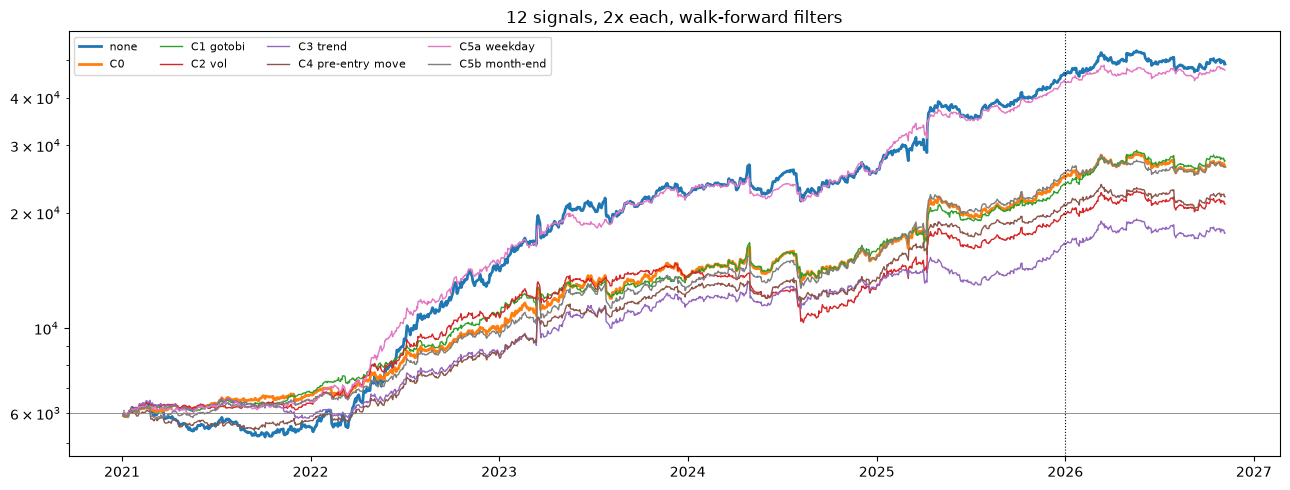

In [6]:
rowsC, curves = [], {}
for c in ["none", "C0", *COND]:
    Nf = NB.copy() if c == "none" else NB.where(pd.DataFrame({i: MASK[(i, c)] for i in SIGNALS}), 0.0)
    for per, sel in (("2021-2026", oos), ("2026", idx.year == 2026)):
        for L in LEVERAGES:
            acc = F.simulate_account(Nf.loc[sel], pd.Series(float(L), index=Nf.columns), E0)
            st = F.account_stats(acc, E0)
            if per == "2021-2026":
                curves[(c, L)] = acc
            rowsC.append({"filter": c, "period": per, "L": L, "final_equity": round(st["final_equity"]), "cagr %": round(100 * st["cagr"], 1),
                          "sharpe": round(st["sharpe"], 2), "max dd %": round(100 * st["max_drawdown"], 1), "worst year %": round(100 * st["worst_year"], 1)})
Ct = pd.DataFrame(rowsC)
Ct.to_csv(OUT / "10_C_portfolio.csv", index=False)
display(Ct.pivot_table(index=["filter"], columns=["period", "L"], values="cagr %").reindex(["none", "C0", *COND]))
display(Ct.pivot_table(index=["filter"], columns=["period", "L"], values="max dd %").reindex(["none", "C0", *COND]))
display(Ct[Ct["L"] == 2].set_index(["filter", "period"]).drop(columns="L"))
fig, ax = plt.subplots(figsize=(13, 5))
for c in ["none", "C0", *COND]:
    ax.plot(curves[(c, 2)]["equity"].clip(lower=1), label=c, lw=2 if c in ("none", "C0") else 1)
ax.axhline(E0, color="grey", lw=0.6); ax.axvline(pd.Timestamp("2026-01-01"), color="black", ls=":", lw=0.8)
ax.set_yscale("log"); ax.set_title("12 signals, 2x each, walk-forward filters"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "10_equity_2x.png", dpi=110); plt.show()

In [7]:
summary = {"study": "FXS10", "prereg": "discussions/FX_Intraday_Seasonality/005_claude_fxs10_conditioners_preregistration.md",
           "synthetic": SYNTHETIC, "signals": {k: list(v) for k, v in SIGNALS.items()}, "commission_usd_per_lot_rt": COMMISSION_PER_LOT,
           "spread_factor": SPREAD_FACTOR, "A_bh_significant": A[A["q"] <= 0.05][["signal", "conditioner", "p", "q"]].to_dict(orient="records"),
           "B_usable": B[B["usable"]].round(4).to_dict(orient="records"), "B": B.round(4).to_dict(orient="records"),
           "C_2x": Ct[Ct["L"] == 2].to_dict(orient="records")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\10\summary.json
